# Intuition

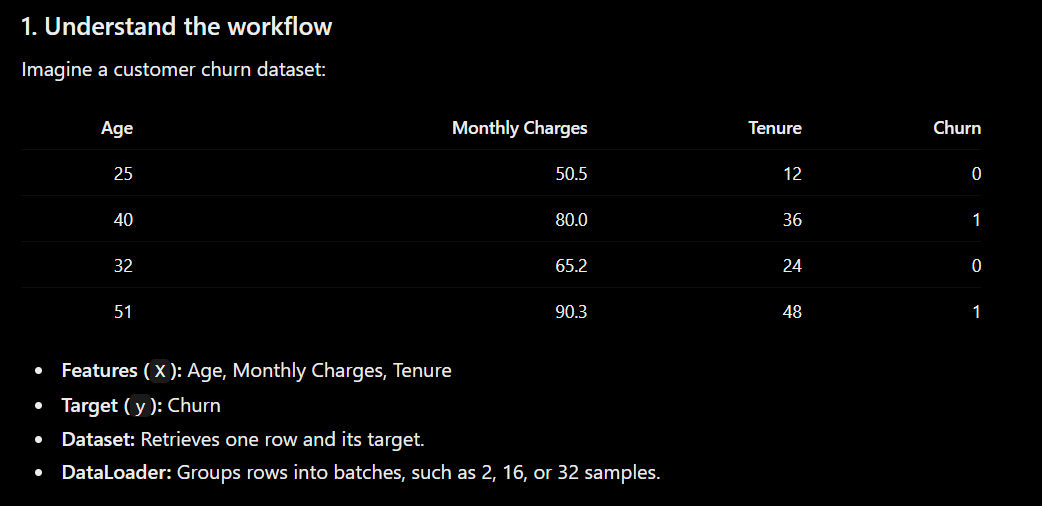

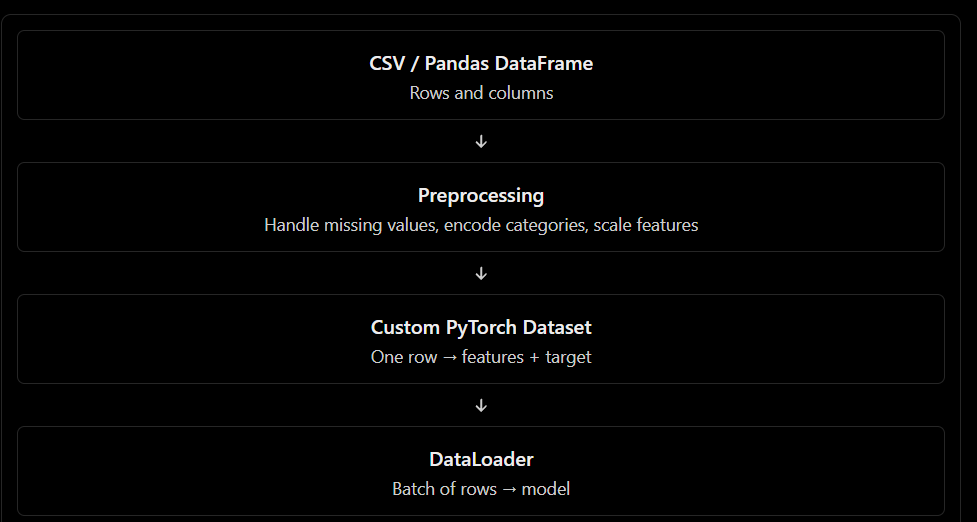

# Load the dataset

In [26]:
import pandas as pd
import numpy as np
import torch

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from torch.utils.data import Dataset, DataLoader

#Load tablur dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data , columns = data.feature_names)

y = pd.Series(data.target , name = "target")




In [18]:
print("Features Shape : ", X.shape)

print("Target Shape : ", y.shape)

print(X.head())

print(y.value_counts())

Features Shape :  (569, 30)
Target Shape :  (569,)
   mean radius  mean texture  ...  worst symmetry  worst fractal dimension
0        17.99         10.38  ...          0.4601                  0.11890
1        20.57         17.77  ...          0.2750                  0.08902
2        19.69         21.25  ...          0.3613                  0.08758
3        11.42         20.38  ...          0.6638                  0.17300
4        20.29         14.34  ...          0.2364                  0.07678

[5 rows x 30 columns]
target
1    357
0    212
Name: count, dtype: int64


# Split the data into training and testing sets

In [19]:
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state= 42,

)

print("Training smaples : ", len(X_train))
print("Testing samples : " , len(X_test))

Training smaples :  455
Testing samples :  114


# Feature Scaling

In [20]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train)
print(X_test)

[[-1.44075296 -0.43531947 -1.36208497 ...  0.9320124   2.09724217
   1.88645014]
 [ 1.97409619  1.73302577  2.09167167 ...  2.6989469   1.89116053
   2.49783848]
 [-1.39998202 -1.24962228 -1.34520926 ... -0.97023893  0.59760192
   0.0578942 ]
 ...
 [ 0.04880192 -0.55500086 -0.06512547 ... -1.23903365 -0.70863864
  -1.27145475]
 [-0.03896885  0.10207345 -0.03137406 ...  1.05001236  0.43432185
   1.21336207]
 [-0.54860557  0.31327591 -0.60350155 ... -0.61102866 -0.3345212
  -0.84628745]]
[[-0.46649743 -0.13728933 -0.44421138 ... -0.19435087  0.17275669
   0.20372995]
 [ 1.36536344  0.49866473  1.30551088 ...  0.99177862 -0.561211
  -1.00838949]
 [ 0.38006578  0.06921974  0.40410139 ...  0.57035018 -0.10783139
  -0.20629287]
 ...
 [-0.73547237 -0.99852603 -0.74138839 ... -0.27741059 -0.3820785
  -0.32408328]
 [ 0.02898271  2.0334026   0.0274851  ... -0.49027026 -1.60905688
  -0.33137507]
 [ 1.87216885  2.80077153  1.80354992 ...  0.7925579  -0.05868885
  -0.09467243]]


Important distinction:
- fit_transform() learns the scaling parameters from training data and transforms it.
- transform() applies those same parameters to test data.
Step 4 — Create your custom Dataset

# Create your custom dataset

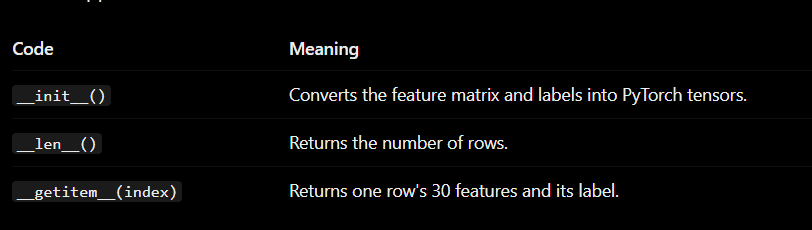

In [21]:
class TabularDataset(Dataset):

    def __init__(self, features, labels):
        self.features = torch.tensor(
            features, dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels.to_numpy() if hasattr(labels, "to_numpy") else labels,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):
        feature = self.features[index]
        label = self.labels[index]

        return feature, label

## Create the Dataset objects:

In [22]:
train_dataset = TabularDataset(X_train, y_train)
test_dataset = TabularDataset(X_test, y_test)

print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))

Training dataset size: 455
Testing dataset size: 114


## Inspect samples

In [23]:
features, label = train_dataset[0]

print("Features:", features)
print("Feature shape:", features.shape)
print("Label:", label)

Features: tensor([-1.4408, -0.4353, -1.3621, -1.1391,  0.7806,  0.7189,  2.8231, -0.1191,
         1.0927,  2.4582, -0.2638, -0.0161, -0.4704, -0.4748,  0.8384,  3.2510,
         8.4389,  3.3920,  2.6212,  2.0612, -1.2329, -0.4763, -1.2479, -0.9740,
         0.7229,  1.1867,  4.6728,  0.9320,  2.0972,  1.8865])
Feature shape: torch.Size([30])
Label: tensor(1.)


# Create DataLoaders

In [27]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 15
Testing batches: 4


## Inspect a batch

In [28]:
for features, labels in train_loader:
    print("Batch features shape:", features.shape)
    print("Batch labels shape:", labels.shape)

    print("\nFirst sample features:")
    print(features[0])

    print("\nFirst sample label:")
    print(labels[0])

    break

Batch features shape: torch.Size([32, 30])
Batch labels shape: torch.Size([32])

First sample features:
tensor([ 0.1592,  0.2218,  0.1176,  0.0850,  0.2104, -0.6033, -0.1883,  0.1134,
        -0.8194, -0.4911,  0.2499,  0.0690,  0.1628,  0.1129, -0.4163, -0.7541,
        -0.4000, -0.1279, -0.7930, -0.6234,  0.5899,  0.8821,  0.4888,  0.4603,
         0.6448, -0.4239,  0.0803,  0.7159,  0.1965, -0.0958])

First sample label:
tensor(0.)


# Train a simple neural network

In [30]:
import torch.nn as nn

torch.manual_seed(42)

model = nn.Sequential(

                      nn.Linear(30,64),
                      nn.ReLU(),
                      nn.Linear(64,1)
)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(10):
    model.train()
    total_loss = 0

    for features, labels in train_loader:
        # Forward pass
        logits = model(features).squeeze(1)

        # Calculate loss
        loss = criterion(logits, labels)

        # Clear old gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/10, "
        f"Loss: {average_loss:.4f}"
    )

Epoch 1/10, Loss: 0.6525
Epoch 2/10, Loss: 0.4976
Epoch 3/10, Loss: 0.3833
Epoch 4/10, Loss: 0.2872
Epoch 5/10, Loss: 0.2336
Epoch 6/10, Loss: 0.1846
Epoch 7/10, Loss: 0.1520
Epoch 8/10, Loss: 0.1330
Epoch 9/10, Loss: 0.1167
Epoch 10/10, Loss: 0.1143


# Evaluate the model on the test set

In [31]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for features, labels in test_loader:
        logits = model(features).squeeze(1)

        predictions = (logits >= 0).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 97.37%
